Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


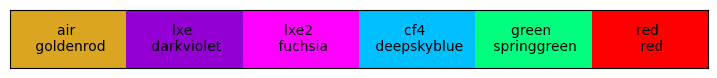

In [1]:
from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
from scipy.stats import norm
from scipy.stats import triang

import iminuit
from iminuit import Minuit
from scipy.ndimage import gaussian_filter1d

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
# from PDEhelpers.PNJunction import *
import PDEhelpers.PNJunction as PNJ

from fittingFunctions import * 

import PDE_fittingTools as SS

import PDEhelpers.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

In [2]:
from fittingFunctions import * 

def quadraticSolution(a, b, c):
    return (-b + np.sqrt(b**2 - 4*a*c))/(2*a), (-b - np.sqrt(b**2 - 4*a*c))/(2*a)

veraFWHM = 9/2.355
FF = 0.8
p = 35 # units of um
h = 1.3

## Case A
case = quadraticSolution(a = 1, b = -p, c = (1-FF)*(p**2)/4)
print("35um pitch, ff: ", case)
ff_fbk = min(case)
print("35um fbk pitch, ff: ", ff_fbk)

Wfbk = ff_fbk/p
Hfbk = h / p
print("relative Width, fbk: ", Wfbk)
print("testing FF func:", FF_theta_relative(Wfbk, Hfbk, 0))

35um pitch, ff:  (33.15247584249853, 1.8475241575014714)
35um fbk pitch, ff:  1.8475241575014714
relative Width, fbk:  0.05278640450004204
testing FF func: 0.8569469387755102


-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


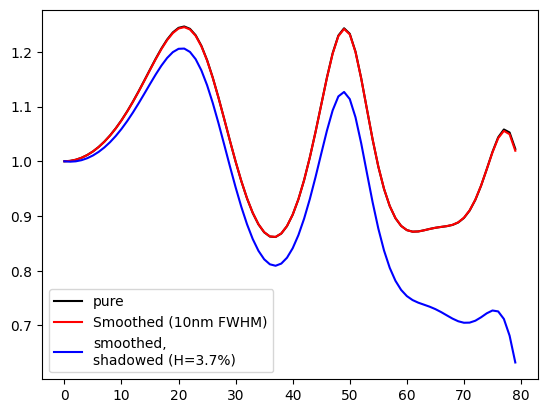

In [3]:
someAngles = np.arange(0, 80, 1)

yPure = RelativeTrans_oxide(wlen=500, tOxide=1500, theta1=someAngles)
ySmoothed = RelativeTrans_oxide(wlen=500, tOxide=1500, theta1=someAngles, smoothSigma=2/2.335)
yShadowed = RelativeTrans_oxide(wlen=500, tOxide=1500, theta1=someAngles, smoothSigma=2/2.335, H=Hfbk)

plt.plot(someAngles, yPure, color="black", label = "pure")
plt.plot(someAngles, ySmoothed, color="red", label = "Smoothed (10nm FWHM)")
plt.plot(someAngles, yShadowed, color="blue", label = f"smoothed,\nshadowed (H={Hfbk*100:.1f}%)")

plt.legend()

In [4]:
print("---- High Res Data ----")

file_pathHR = os.path.join(PROPATH, "../veraData/FBK_angular_current.csv")

df = pd.read_csv(file_pathHR, header=0)
print(df.head())
print(df.tail())


# data_anglesHR = df['Angle'].unique()
dfNames = df.columns
print(dfNames.values)
strV = dfNames[0]
strI = dfNames[1]
strA = dfNames[2]
strWlen = dfNames[3]

data_voltages = df[strV].unique()
data_wlensAll = df[strWlen].unique()

print("voltages:", data_voltages)
print("wavelengths:", data_wlensAll)

# print("wlen range:", df['Wavelength'].min(), df['Wavelength'].max())

---- High Res Data ----
   Bias Voltage (V)   Photo-Current (A)   Angle (deg)   Wavelength (nm)
0             28.63        6.676270e-08             0           165.005
1             28.63        7.092270e-08             2           165.005
2             28.63        7.407640e-08             4           165.005
3             28.63        7.278870e-08             6           165.005
4             28.63        7.271470e-08             8           165.005
     Bias Voltage (V)   Photo-Current (A)   Angle (deg)   Wavelength (nm)
739             34.63        3.398350e-07            52           799.921
740             34.63        3.774290e-07            54           799.921
741             34.63        3.630100e-07            56           799.921
742             34.63        3.382370e-07            58           799.921
743             34.63        3.228320e-07            60           799.921
['Bias Voltage (V)' ' Photo-Current (A)' ' Angle (deg)' ' Wavelength (nm)']
voltages: [28.63 30.63 3

In [5]:
class AngularObject:
    
    def __init__(self, df, voltage, wavelength):
        self.df = df
        self.voltage = voltage
        self.wavelength = wavelength
        self.dfV = df[df[strV] == voltage]
        self.dfVW = self.dfV[self.dfV[strWlen] == wavelength]
        self.angles = self.dfVW[strA].values
        self.currents = self.dfVW[strI].values
        self.normCurrent = self.currents - np.min(self.currents)
        # self.currents = self.currents / np.max(self.currents)
        # self.currents = self.currents * 1000

[165.005 164.948 164.976 169.915 169.887 399.975 399.946 400.004 434.953
 435.011 434.982 599.981 600.01  799.95  799.921]
[165.005, 169.915, 399.975, 434.953, 599.981, 799.95]
wl: 165.005
wl: 169.915
wl: 399.975
wl: 434.953
wl: 599.981
wl: 799.95


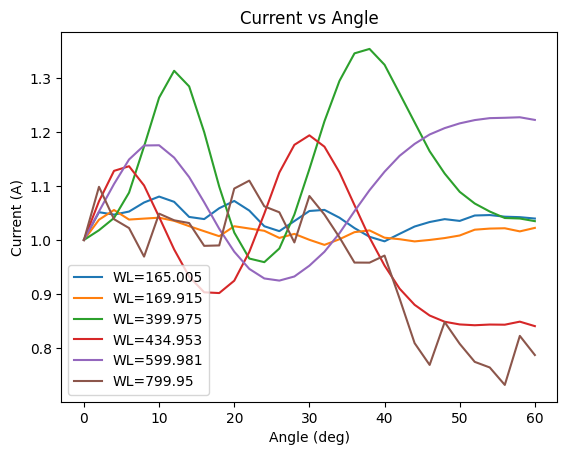

In [6]:
vPick = data_voltages[2]

wlenBuf = 2.
properwlens = []
for i, wlen in enumerate(data_wlensAll):
    if abs(data_wlensAll[i - 2] - wlen) < wlenBuf or abs(data_wlensAll[i - 1] - wlen) < wlenBuf:
        continue
    else:
        properwlens.append(wlen)

print(data_wlensAll)
print(properwlens)
data_wlensAll = properwlens

for wl in data_wlensAll:
    df_wl = df[(df[strWlen] > wl - wlenBuf) & (df[strWlen] < wl + wlenBuf) & (df[strV] == vPick)]
    print("wl:", wl)
    
    currentNormal = df_wl.loc[df_wl[strA].abs().idxmin()][strI] # get value for zero
    currentZero = df_wl.loc[df_wl[strA]==0][strI].values[0]
    if currentZero != currentNormal:
        print("issue with finding zero current")
        break
    
    xAngle = df_wl[strA].values
        
    yCurrent = df_wl[strI].values
    yNorm = yCurrent/currentNormal

    plt.plot(xAngle, yNorm, label=f"WL={wl}")

plt.legend()
plt.title("Current vs Angle")
plt.xlabel("Angle (deg)")
plt.ylabel("Current (A)")
plt.legend()
plt.show()

selectWlens: [399.975, 434.953, 599.981]
wl: 399.975
wl: 434.953
wl: 599.981
5.732484076433121


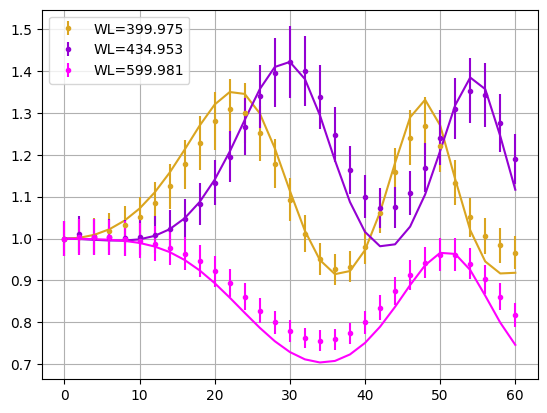

In [14]:
selectWlens = data_wlensAll[2:5]
print("selectWlens:", selectWlens)
ms = MS.MyStyleSet()

veraWidth = 10/2.335
errorFraction = 0.03

for wl in selectWlens:
    df_wl = df[(df[strWlen] > wl - wlenBuf) & (df[strWlen] < wl + wlenBuf) & (df[strV] == vPick)]
    print("wl:", wl)
    
    
    # currentNormal = df_wl.loc[df_wl[strA].abs().idxmax()][strI] # get value for zero (max Angle)
    # currentNormError = currentNormal * errorFraction
      
    xAngle = df_wl[strA].values
    xAngle = max(xAngle) - xAngle
    # xAngle = 60 - xAngle
    
    yCurrent = df_wl[strI].values
    yCurrentError = yCurrent * errorFraction
    
    # get the two yCurrent values for xAngle < cutoff
    cutoff = 2
    currentNormal = np.average(yCurrent[xAngle < cutoff])
    currentNormError = currentNormal * errorFraction / np.sqrt(len(yCurrent[xAngle < cutoff]))
        
    yNorm = yCurrent/currentNormal
    yNormErrors = yNorm*np.sqrt((yCurrentError/currentNormal)**2 + (yNorm * currentNormError/currentNormal)**2)

    plt.errorbar(xAngle, yNorm, yerr=yNormErrors, label=f"WL={wl}", marker=".", linestyle="None", color=ms.GetNextColor())
    
    # guess
    yGuess = RelativeTrans_oxide(wlen=wl, tOxide=1339.5, theta1=xAngle, smoothSigma=veraFWHM, H=0.01)
    plt.plot(xAngle, yGuess, linestyle="-", color=ms.GetNextColor(1))
    
    # yGuess2 = RelativeTrans_oxide(wlen=wl, tOxide=1339.5, theta1=xAngle, smoothSigma=5.9, H=0.00)
    # plt.plot(xAngle, yGuess2, linestyle="--", color=ms.GetNextColor(1))


print(veraFWHM*1.5)
plt.grid()
plt.legend()

In [8]:
# Building dataset for fitting. No Nuisance parameters
dataObj = []
dataPNobj = []

for wl in selectWlens:
    df_wl = df[(df[strWlen] > wl - wlenBuf) & (df[strWlen] < wl + wlenBuf) & (df[strV] == vPick)]
    print("wl:", wl)
      
    xAngle = df_wl[strA].values
    # xAngle = max(xAngle) - xAngle
    xAngle = 60 - xAngle
    
    yCurrent = df_wl[strI].values
    yCurrentError = yCurrent * errorFraction
    
    cutoff = 4
    currentNormal = np.average(yCurrent[xAngle < cutoff])
    currentNormError = currentNormal * errorFraction / np.sqrt(len(yCurrent[xAngle < cutoff]))
    yNorm = yCurrent/currentNormal
    yNormErrors = yNorm*np.sqrt((yCurrentError/currentNormal)**2 + (yNorm * currentNormError/currentNormal)**2)
        
    thisData = {"wlen":wl, "theta1":xAngle, "yVals":yNorm, "yErrs":yNormErrors}
    thisDataPN = {"wlen":wl, "theta1":xAngle, "yVals":yNorm, "yErrs":yNormErrors}
    
    dataObj.append(thisData)
    dataPNobj.append(thisDataPN)

wl: 399.975
wl: 434.953
wl: 599.981


In [9]:
parsFixed = {"W":Wfbk, "H":0.0, "dataHelper": None, "window":False, "smoothSigma": veraFWHM}
# wlen, tOxide, theta1, FF = 1.0, 

parsFloat = {"tOxide":1339.0}
floatBounds = {"tOxide": (1200, 1500)} #"smoothSigma": (-10, 100)
x0, x0Name = SS.BuildX0(parsFloat, RelativeTrans_oxide)
x0Bounds = SS.BuildX0_bounds(floatBounds, RelativeTrans_oxide)

SS.CheckAllConditions_forResiduals(func=RelativeTrans_oxide, dataObj=dataObj, dFixed=parsFixed, dFloat=parsFloat,
                                   yNames=("yVals", "yErrs"), verbose=False)

a = SS.GenericResiduals(x0=x0, dataObj = dataObj,
                               functionToFit=RelativeTrans_oxide,
                               fixedArgs_dict = parsFixed,
                               verbose=True, yNames = ("yVals", "yErrs"))
print("Guess score:", a)

------- GenericResiduals(function=RelativeTrans_oxide) -------
	all input parameters (except data):  ['tOxide', 'W', 'H', 'smoothSigma', 'dataHelper', 'window']
	floating args:  ['tOxide']
	---------------- data block 0 --------------------
		float dict (from x0): {'tOxide': 1339.0}
		fixed dict: {'W': 0.05278640450004204, 'H': 0.0, 'dataHelper': None, 'window': False, 'smoothSigma': 3.821656050955414}
		dataDict for function, (keys): {'wlen': 399.975, 'theta1': [60, 58, 56, '...']}
		dataDict for data (y): {'yVals': [0.9640544854913338, 0.9814195074913499, 1.0032493578264148, '...'], 'yErrs': [0.03414837512019765, 0.035389649100189755, 0.036981512139419734, '...']}
	---------------- data block 1 --------------------
		float dict (from x0): {'tOxide': 1339.0}
		fixed dict: {'W': 0.05278640450004204, 'H': 0.0, 'dataHelper': None, 'window': False, 'smoothSigma': 3.821656050955414}
		dataDict for function, (keys): {'wlen': 434.953, 'theta1': [60, 58, 56, '...']}
		dataDict for data (y): {

In [10]:
## doing fit
fitResult = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds,
                             args=(parsFixed, dataObj, RelativeTrans_oxide),
                             method='migrad', options={'stra': 2, "maxfun": 1000})
print(fitResult)

resultDict = SS.GetResDict(fitResult, x0Name)
errorDict = SS.GetResErrorDict(fitResult, x0Name)
print("score:", fitResult.fun)
print(resultDict)
print(errorDict)

  message: Optimization terminated successfully.
  success: True
      fun: 69.10749697586822
        x: [ 1.339e+03]
 hess_inv: ┌────┬──────┐
           │    │   x0 │
           ├────┼──────┤
           │ x0 │ 0.33 │
           └────┴──────┘
     nfev: 18
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 69.11                      │              Nfcn = 18               │
           │ EDM = 2.73e-12 (Goal: 0.0001)    │            time = 0.9 sec            │
           ├──────────────────────────────────┼──────────────────────────────────────┤
           │          Valid Minimum           │   Below EDM threshold (goal x 10)    │
           ├──────────────────────────────────┼──────────────────────────────────────┤
           │      No parameters at

---
### Full Relative PDE equation

In [11]:
# pars fixed Full

allArgs = SS.GetFuncArgs(RelativePDE_angle)
print(allArgs)

parsPN_Fixed = {"tOxide":1339.0, "FF":0.8, "dp_star":1.26, "Xpn":320, "dw_star": 4.4e3, "quantum": False, "dh": None, "smoothSigma": veraFWHM}
# wlen, tOxide, theta1, FF = 1.0, 

parsFloat = {"pe":0.9, "ph":0.3}
floatBounds = {"pe":(0.0, 1.1), "ph": (0.0, 1.1)} #"tOxide": (1200, 1500) #"smoothSigma": (-10, 100)
x0, x0Name = SS.BuildX0(parsFloat, RelativePDE_angle)
x0Bounds = SS.BuildX0_bounds(floatBounds, RelativePDE_angle)

SS.CheckAllConditions_forResiduals(func=RelativePDE_angle, dataObj=dataPNobj, dFixed=parsPN_Fixed, dFloat=parsFloat,
                                   yNames=("yVals", "yErrs"), verbose=False)

a = SS.GenericResiduals(x0=x0, dataObj = dataPNobj,
                               functionToFit=RelativePDE_angle,
                               fixedArgs_dict = parsPN_Fixed,
                               verbose=True, yNames = ("yVals", "yErrs"))
print("Guess score:", a)

ndof = sum([len(do["theta1"]) for do in dataPNobj]) - len(parsFloat) - len(parsPN_Fixed)
print("reduced score:", a/ndof)

['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']
------- GenericResiduals(function=RelativePDE_angle) -------
	all input parameters (except data):  ['FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']
	floating args:  ['pe', 'ph']
	---------------- data block 0 --------------------
		float dict (from x0): {'pe': 0.9, 'ph': 0.3}
		fixed dict: {'tOxide': 1339.0, 'FF': 0.8, 'dp_star': 1.26, 'Xpn': 320, 'dw_star': 4400.0, 'quantum': False, 'dh': None, 'smoothSigma': 3.821656050955414}
		dataDict for function, (keys): {'wlen': 399.975, 'theta1': [60, 58, 56, '...']}
		dataDict for data (y): {'yVals': [0.9640544854913338, 0.9814195074913499, 1.0032493578264148, '...'], 'yErrs': [0.03414837512019765, 0.035389649100189755, 0.036981512139419734, '...']}
	---------------- data block 1 --------------------
		float dict (from x0): {'pe': 0.9, 'ph': 0.3}
		fixed dict: {'tOxide': 1339.0, 'FF': 0.8, 'dp_st

In [12]:
## doing the PN fit
PNfitResult = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds,
                             args=(parsPN_Fixed, dataPNobj, RelativePDE_angle),
                             method='migrad', options={'stra': 2, "maxfun": 1000})
print(PNfitResult)

resultDictPN = SS.GetResDict(PNfitResult, x0Name)
errorDictPN = SS.GetResErrorDict(PNfitResult, x0Name)
print("score:", PNfitResult.fun)
print(resultDictPN)
print(errorDictPN)

  message: Optimization terminated successfully, but uncertainties are unrealiable.
  success: True
      fun: 61.624437922367676
        x: [ 4.139e-01  1.648e-11]
 hess_inv: ┌────┬───────────────────────────────────┐
           │    │               x0               x1 │
           ├────┼───────────────────────────────────┤
           │ x0 │         1.29e+09 111.190243624e-3 │
           │ x1 │ 111.190243624e-3         9.58e-12 │
           └────┴───────────────────────────────────┘
     nfev: 81
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 61.62                      │              Nfcn = 81               │
           │ EDM = 1.86e-09 (Goal: 0.0001)    │            time = 4.1 sec            │
           ├──────────────────────────────────┼──